<div align="center">
<br>

# Turning Data into Insight

*Data analysis with pandas and Matplotlib — live coding session.*  
*Read the data, describe it, and answer simple questions.*

<br>
</div>

<div style="margin:0 0 24px;padding:14px 20px;border-radius:8px;border:1px solid #e0e7ff;background:#fafafe;font-family:'Inter','Segoe UI',sans-serif;">
  <div style="font-size:0.88em;font-weight:700;letter-spacing:1.8px;text-transform:uppercase;color:#6366f1;margin-bottom:6px;">Dataset</div>
  <div style="font-size:0.95em;font-weight:700;color:#1e1b4b;margin-bottom:3px;">50 Startups</div>
  <div style="font-size:0.82em;color:#6b7280;">50 startups (samples), each described by 5 features: R&amp;D Spend, Administration, Marketing Spend, State and Profit. You are the data analyst.</div>
</div>

<div style="border-top:4px solid;border-image:linear-gradient(90deg,#4f46e5,#7c3aed) 1;background:#fafafe;border-radius:0 0 10px 10px;padding:20px 24px 10px;margin:16px 0 4px;box-shadow:0 3px 16px rgba(99,102,241,0.12);"><span style="float:right;font-size:1.8rem;opacity:0.15;">📦</span><kbd>SECTION 00</kbd>

## Install & Imports</div>

<div style="margin:20px 0 4px;border-radius:8px;overflow:hidden;border:1px solid #bfdbfe;background:#eff6ff;"><div style="height:3px;background:#2563eb;"></div><div style="padding:12px 18px 13px;"><span style="font-size:0.68em;font-weight:800;letter-spacing:1px;color:#1d4ed8;text-transform:uppercase;">Step 1</span>&nbsp;&nbsp;<span style="font-size:1em;font-weight:700;color:#1e3a8a;">Install the libraries</span></div></div>

Run this cell once. It installs pandas and Matplotlib. (On Google Colab they are already installed, so you can skip it.)

In [ ]:
%pip install pandas matplotlib

<div style="margin:20px 0 4px;border-radius:8px;overflow:hidden;border:1px solid #bfdbfe;background:#eff6ff;"><div style="height:3px;background:#2563eb;"></div><div style="padding:12px 18px 13px;"><span style="font-size:0.68em;font-weight:800;letter-spacing:1px;color:#1d4ed8;text-transform:uppercase;">Step 2</span>&nbsp;&nbsp;<span style="font-size:1em;font-weight:700;color:#1e3a8a;">Import the libraries</span></div></div>

Load the two libraries we need, with the short names everyone uses.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

<div style="border-top:4px solid;border-image:linear-gradient(90deg,#0ea5e9,#6366f1) 1;background:#fafafe;border-radius:0 0 10px 10px;padding:20px 24px 10px;margin:32px 0 4px;box-shadow:0 3px 16px rgba(99,102,241,0.12);"><span style="float:right;font-size:1.8rem;opacity:0.15;">🔍</span><kbd>SECTION 01</kbd>

## Meet the Dataset</div>

<div style="margin:20px 0 4px;border-radius:8px;overflow:hidden;border:1px solid #bfdbfe;background:#eff6ff;"><div style="height:3px;background:#2563eb;"></div><div style="padding:12px 18px 13px;"><span style="font-size:0.68em;font-weight:800;letter-spacing:1px;color:#1d4ed8;text-transform:uppercase;">Step 1</span>&nbsp;&nbsp;<span style="font-size:1em;font-weight:700;color:#1e3a8a;">Read the data</span></div></div>

Before anything else, load the file and look at it. Each **row** is one startup (a sample). Each **column** is one feature.

In [5]:
URL = "https://raw.githubusercontent.com/dinesh19aug/ml-notes/master/Part-4-multiple-regression/50_Startups.csv"
df = pd.read_csv(URL)

df.shape

(50, 5)

In [6]:
df.head()

,R&D Spend,Administration,Marketing Spend,State,Profit
0,165349.20,136897.80,471784.10,New York,192261.83
1,162597.70,151377.59,443898.53,California,191792.06
2,153441.51,101145.55,407934.54,Florida,191050.39
3,144372.41,118671.85,383199.62,New York,182901.99
4,142107.34,91391.77,366168.42,Florida,166187.94


<div style="margin:20px 0 4px;border-radius:8px;overflow:hidden;border:1px solid #bfdbfe;background:#eff6ff;"><div style="height:3px;background:#2563eb;"></div><div style="padding:12px 18px 13px;"><span style="font-size:0.68em;font-weight:800;letter-spacing:1px;color:#1d4ed8;text-transform:uppercase;">Step 2</span>&nbsp;&nbsp;<span style="font-size:1em;font-weight:700;color:#1e3a8a;">Describe the dataset</span></div></div>

What type is each column? Is anything missing? What do the numbers look like on average?

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   R&D Spend        50 non-null     float64
 1   Administration   50 non-null     float64
 2   Marketing Spend  50 non-null     float64
 3   State            50 non-null     object 
 4   Profit           50 non-null     float64
dtypes: float64(4), object(1)
memory usage: 2.1+ KB


### Missing values per column

In [10]:
df.isnull().sum()

R&D Spend          0
Administration     0
Marketing Spend    0
State              0
Profit             0
dtype: int64

In [12]:
df.describe().round(2)

,R&D Spend,Administration,Marketing Spend,Profit
count,50.00,50.00,50.00,50.00
mean,73721.62,121344.64,211025.10,112012.64
std,45902.26,28017.80,122290.31,40306.18
min,0.00,51283.14,0.00,14681.40
25%,39936.37,103730.88,129300.13,90138.90
50%,73051.08,122699.80,212716.24,107978.19
75%,101602.80,144842.18,299469.08,139765.98
max,165349.20,182645.56,471784.10,192261.83


In [15]:
df[df["Profit"] == min(df["Profit"])]

,R&D Spend,Administration,Marketing Spend,State,Profit
49,0.0,116983.8,45173.06,California,14681.4


In [16]:
df[df["Profit"] == max(df["Profit"])]

,R&D Spend,Administration,Marketing Spend,State,Profit
0,165349.2,136897.8,471784.1,New York,192261.83


In [20]:
df["State"].unique()

array(['New York', 'California', 'Florida'], dtype=object)

In [22]:
df["State"].value_counts()

State
New York      17
California    17
Florida       16
Name: count, dtype: int64

<div style="border-top:4px solid;border-image:linear-gradient(90deg,#10b981,#06b6d4) 1;background:#fafafe;border-radius:0 0 10px 10px;padding:20px 24px 10px;margin:32px 0 4px;box-shadow:0 3px 16px rgba(16,185,129,0.12);"><span style="float:right;font-size:1.8rem;opacity:0.15;">🎯</span><kbd>SECTION 02</kbd>

## Simple Questions</div>

<div style="margin:20px 0 4px;border-radius:8px;overflow:hidden;border:1px solid #a7f3d0;background:#f0fdf4;"><div style="height:3px;background:#059669;"></div><div style="padding:12px 18px 13px;"><span style="font-size:0.68em;font-weight:800;letter-spacing:1px;color:#047857;text-transform:uppercase;">Question </span>&nbsp;&nbsp;<span style="font-size:1em;font-weight:700;color:#064e3b;">Which type of spending moves with profit?</span></div></div>

One scatter plot per feature: if the dots rise from left to right, more spending goes with more profit.

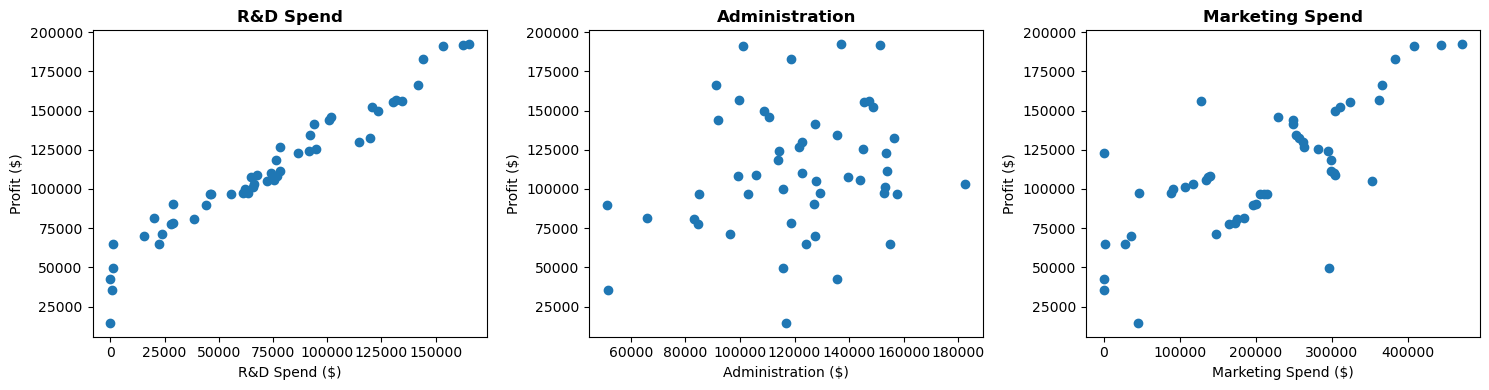

In [40]:
features = ['R&D Spend', 'Administration', 'Marketing Spend']

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, feat in zip(axes, features):
    ax.scatter(df[feat], df['Profit'])
    ax.set_xlabel(f'{feat} ($)')
    ax.set_ylabel('Profit ($)')
    ax.set_title(feat, fontweight='bold')

plt.tight_layout()
plt.show()

The correlation puts a number on what we see: close to 1 means a strong link, close to 0 means almost none.

In [36]:
features = ['R&D Spend', 'Administration', 'Marketing Spend', "Profit"]

df[features].corr()['Profit']

R&D Spend          0.972900
Administration     0.200717
Marketing Spend    0.747766
Profit             1.000000
Name: Profit, dtype: float64

<div style="margin:20px 0 4px;border-radius:8px;overflow:hidden;border:1px solid #a7f3d0;background:#f0fdf4;"><div style="height:3px;background:#059669;"></div><div style="padding:12px 18px 13px;"><span style="font-size:0.68em;font-weight:800;letter-spacing:1px;color:#047857;text-transform:uppercase;">Question </span>&nbsp;&nbsp;<span style="font-size:1em;font-weight:700;color:#064e3b;">Does location make a difference?</span></div></div>

Group the startups by `State` and compare their average profit.

In [43]:
df.groupby('State')['Profit'].agg(['count', 'mean']).round(0)

,count,mean
State,,
California,17,103905.0
Florida,16,118774.0
New York,17,113756.0


<span style="font-size:0.72em;font-weight:700;letter-spacing:1.8px;text-transform:uppercase;color:#9ca3af;">Takeaways</span>

- **R&D Spend moves with Profit the most** (correlation ≈ 0.97). Marketing is a clear second (≈ 0.75). Administration has only a weak link (≈ 0.20).
- **Location shows a small difference.** Florida has the highest average profit and California the lowest.
- **Next step:** with these answers we can start asking a bigger question: can we *predict* a startup's profit from its spending?
